# Logistic Regression - Malka H. A. G. (IT25102115)


## 1. Model Suitability

**Why Logistic Regression for Wisconsin Breast Cancer data?**

- The target is **binary** (benign/malignant) then logistic regression is the classic linear probabilistic classifier.
- Features are continuous / ordinal (1–10 scale) and after preprocessing are standardized then linear decision boundary is appropriate.
- Dataset is relatively small (~700 samples) and linearly separable to a good degree (PCA showed clear clusters) then logistic regression is robust, interpretable and less prone to overfitting than complex models.
- Provides class probabilities which are clinically useful.
- Fast to train and easy to tune (regularization strength `C`, penalty type).


In [ ]:
# Standard libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================================
# GOOGLE DRIVE MOUNT & LOAD PREPROCESSED DATA
# Student: Malka H. A. G. (IT25102115)
# Algorithm: Logistic Regression
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

# >>> UPDATE THIS PATH to your Google Drive folder containing the preprocessed CSV <<<
DATA_PATH = '/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/results/outputs/processed_breast_cancer.csv'

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nClass distribution:")
print(df['Class'].value_counts())
df.head()

Mounted at /content/drive
Dataset shape: (699, 20)

Columns: ['Sample_code_number', 'Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape', 'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei', 'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses', 'Clump_Thickness_scaled', 'Uniformity_of_Cell_Size_scaled', 'Uniformity_of_Cell_Shape_scaled', 'Marginal_Adhesion_scaled', 'Single_Epithelial_Cell_Size_scaled', 'Bare_Nuclei_scaled', 'Bland_Chromatin_scaled', 'Normal_Nucleoli_scaled', 'Mitoses_scaled', 'Class']

Class distribution:
Class
0    458
1    241
Name: count, dtype: int64


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Clump_Thickness_scaled,Uniformity_of_Cell_Size_scaled,Uniformity_of_Cell_Shape_scaled,Marginal_Adhesion_scaled,Single_Epithelial_Cell_Size_scaled,Bare_Nuclei_scaled,Bland_Chromatin_scaled,Normal_Nucleoli_scaled,Mitoses_scaled,Class
0,1000025,5.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,0.206936,-0.699995,-0.743299,-0.633247,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0
1,1002945,5.0,4.0,4.0,5.0,7.0,10.0,3.0,2.0,1.0,0.206936,0.283845,0.266875,0.768621,1.710106,1.799664,-0.179662,-0.284112,-0.343912,0
2,1015425,3.0,1.0,1.0,1.0,2.0,2.0,3.0,1.0,1.0,-0.503866,-0.699995,-0.743299,-0.633247,-0.549561,-0.410685,-0.179662,-0.611825,-0.343912,0
3,1016277,6.0,8.0,8.0,1.0,3.0,4.0,3.0,7.0,1.0,0.562336,1.595632,1.613773,-0.633247,-0.097628,0.141902,-0.179662,1.354454,-0.343912,0
4,1017023,4.0,1.0,1.0,3.0,2.0,1.0,3.0,1.0,1.0,-0.148465,-0.699995,-0.743299,0.067687,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0


In [ ]:
# ============================================================
# DATA PREPARATION
# ============================================================

# Drop identifier column
df = df.drop(columns=['Sample_code_number'], errors='ignore')

# Original (unscaled) features
feature_cols_orig = [
    'Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape',
    'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei',
    'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses'
]

# Scaled features (already standardized in preprocessing pipeline)
feature_cols_scaled = [c + '_scaled' for c in feature_cols_orig]

X_orig = df[feature_cols_orig].values
X_scaled = df[feature_cols_scaled].values
y = df['Class'].values

print("Original features shape:", X_orig.shape)
print("Scaled features shape  :", X_scaled.shape)
print("Target shape           :", y.shape)
print("Class balance          :", np.bincount(y))

Original features shape: (699, 9)
Scaled features shape  : (699, 9)
Target shape           : (699,)
Class balance          : [458 241]


In [ ]:
# ============================================================
# TRAIN / TEST SPLIT (Stratified 80/20)
# ============================================================

X_train_orig, X_test_orig, y_train, y_test = train_test_split(
    X_orig, y, test_size=0.20, random_state=42, stratify=y
)

X_train_scaled, X_test_scaled, _, _ = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)

print("Train size:", X_train_orig.shape[0])
print("Test size :", X_test_orig.shape[0])
print("Train class distribution:", np.bincount(y_train))
print("Test class distribution :", np.bincount(y_test))

Train size: 559
Test size : 140
Train class distribution: [366 193]
Test class distribution : [92 48]


In [ ]:
# ============================================================
# EVALUATION HELPER FUNCTION
# ============================================================

def evaluate_model(model, X_train, X_test, y_train, y_test, model_name="Model"):
    """Train, predict and return comprehensive metrics."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Probability for ROC-AUC if available
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test)
    else:
        y_prob = y_pred  # fallback

    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob) if len(np.unique(y_prob)) > 1 else 0.0
    }

    print(f"\n========== {model_name} ==========")
    print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print(f"ROC-AUC: {metrics['ROC-AUC']:.4f}")

    return metrics, y_pred, y_prob

## 2. Implementation – Logistic Regression Varieties

We will train **4 varieties**:

| Variety | Preprocessing | Hyperparameters |
|---------|---------------|----------------|
| V1 Baseline | Scaled features | Default (`C=1.0`, L2) |
| V2 Manual Tuning | Scaled features | Manually chosen `C` & penalty |
| V3 GridSearchCV | Scaled features | Full grid search + Stratified 5-Fold |
| V4 Original Features | Unscaled (raw) features | Best params from GridSearch |

**Libraries used:** `sklearn.linear_model.LogisticRegression`, `GridSearchCV`, `StratifiedKFold`


In [ ]:
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# Variety 1 – Baseline (default hyperparameters, scaled data)
# ------------------------------------------------------------
lr_v1 = LogisticRegression(random_state=42, max_iter=1000)
metrics_v1, y_pred_v1, y_prob_v1 = evaluate_model(
    lr_v1, X_train_scaled, X_test_scaled, y_train, y_test,
    model_name="V1: Logistic Regression (Baseline, Scaled)"
)


========== V1: Logistic Regression (Baseline, Scaled) ==========
               precision    recall  f1-score   support

   Benign (0)       0.96      0.97      0.96        92
Malignant (1)       0.94      0.92      0.93        48

     accuracy                           0.95       140
    macro avg       0.95      0.94      0.94       140
 weighted avg       0.95      0.95      0.95       140

Confusion Matrix:
[[89  3]
 [ 4 44]]
ROC-AUC: 0.9950


In [ ]:
# ------------------------------------------------------------
# Variety 2 – Manual Hyperparameter Tuning
# ------------------------------------------------------------
# Stronger regularization (smaller C) often helps on small medical datasets
lr_v2 = LogisticRegression(
    C=0.1,               # stronger L2 regularization
    penalty='l2',
    solver='lbfgs',
    max_iter=2000,
    random_state=42
)
metrics_v2, y_pred_v2, y_prob_v2 = evaluate_model(
    lr_v2, X_train_scaled, X_test_scaled, y_train, y_test,
    model_name="V2: Logistic Regression (Manual C=0.1, L2)"
)


========== V2: Logistic Regression (Manual C=0.1, L2) ==========
               precision    recall  f1-score   support

   Benign (0)       0.97      0.97      0.97        92
Malignant (1)       0.94      0.94      0.94        48

     accuracy                           0.96       140
    macro avg       0.95      0.95      0.95       140
 weighted avg       0.96      0.96      0.96       140

Confusion Matrix:
[[89  3]
 [ 3 45]]
ROC-AUC: 0.9948


In [ ]:
# ------------------------------------------------------------
# Variety 3 – GridSearchCV with Stratified 5-Fold CV
# ------------------------------------------------------------
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear'],          # supports both L1 & L2
    'max_iter': [2000]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_lr = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',                    # F1 is appropriate for slightly imbalanced medical data
    n_jobs=-1,
    verbose=1
)

grid_lr.fit(X_train_scaled, y_train)

print("Best parameters :", grid_lr.best_params_)
print("Best CV F1 score:", grid_lr.best_score_)

lr_v3 = grid_lr.best_estimator_
metrics_v3, y_pred_v3, y_prob_v3 = evaluate_model(
    lr_v3, X_train_scaled, X_test_scaled, y_train, y_test,
    model_name="V3: Logistic Regression (GridSearchCV Best)"
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters : {'C': 0.01, 'max_iter': 2000, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV F1 score: 0.9591591741591742

========== V3: Logistic Regression (GridSearchCV Best) ==========
               precision    recall  f1-score   support

   Benign (0)       0.98      0.97      0.97        92
Malignant (1)       0.94      0.96      0.95        48

     accuracy                           0.96       140
    macro avg       0.96      0.96      0.96       140
 weighted avg       0.96      0.96      0.96       140

Confusion Matrix:
[[89  3]
 [ 2 46]]
ROC-AUC: 0.9939


In [ ]:
# ------------------------------------------------------------
# Variety 4 – Best params on ORIGINAL (unscaled) features
# ------------------------------------------------------------
lr_v4 = LogisticRegression(**grid_lr.best_params_, random_state=42)
metrics_v4, y_pred_v4, y_prob_v4 = evaluate_model(
    lr_v4, X_train_orig, X_test_orig, y_train, y_test,
    model_name="V4: Logistic Regression (Best params, Unscaled)"
)


========== V4: Logistic Regression (Best params, Unscaled) ==========
               precision    recall  f1-score   support

   Benign (0)       0.91      0.90      0.91        92
Malignant (1)       0.82      0.83      0.82        48

     accuracy                           0.88       140
    macro avg       0.86      0.87      0.87       140
 weighted avg       0.88      0.88      0.88       140

Confusion Matrix:
[[83  9]
 [ 8 40]]
ROC-AUC: 0.8933


## 3. Comparison Across Varieties


In [ ]:
# Collect all metrics into a DataFrame
results_df = pd.DataFrame([metrics_v1, metrics_v2, metrics_v3, metrics_v4])
results_df = results_df.set_index('Model')
print(results_df.round(4).to_string())

# Highlight best
print("\n>>> Best Accuracy :", results_df['Accuracy'].idxmax(), f"({results_df['Accuracy'].max():.4f})")
print(">>> Best F1-Score :", results_df['F1-Score'].idxmax(), f"({results_df['F1-Score'].max():.4f})")
print(">>> Best ROC-AUC  :", results_df['ROC-AUC'].idxmax(), f"({results_df['ROC-AUC'].max():.4f})")

                                                 Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                                                          
V1: Logistic Regression (Baseline, Scaled)         0.9500     0.9362  0.9167    0.9263   0.9950
V2: Logistic Regression (Manual C=0.1, L2)         0.9571     0.9375  0.9375    0.9375   0.9948
V3: Logistic Regression (GridSearchCV Best)        0.9643     0.9388  0.9583    0.9485   0.9939
V4: Logistic Regression (Best params, Unscaled)    0.8786     0.8163  0.8333    0.8247   0.8933

>>> Best Accuracy : V3: Logistic Regression (GridSearchCV Best) (0.9643)
>>> Best F1-Score : V3: Logistic Regression (GridSearchCV Best) (0.9485)
>>> Best ROC-AUC  : V1: Logistic Regression (Baseline, Scaled) (0.9950)


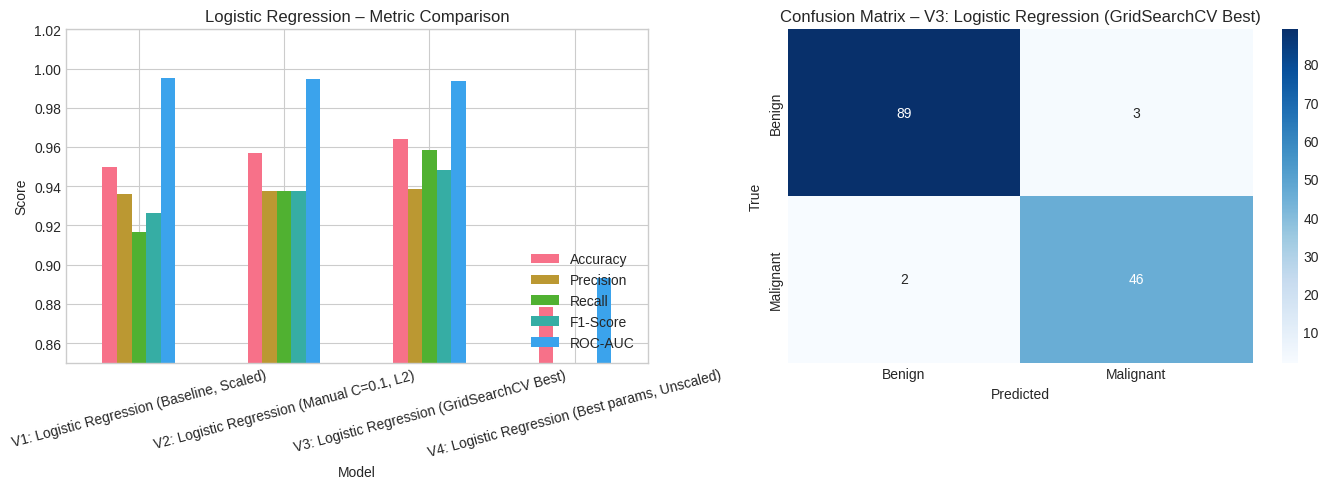

In [ ]:
# Bar chart comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
results_df[metrics_to_plot].plot(kind='bar', ax=axes[0], rot=15)
axes[0].set_title('Logistic Regression – Metric Comparison')
axes[0].set_ylabel('Score')
axes[0].legend(loc='lower right')
axes[0].set_ylim(0.85, 1.02)

# Confusion matrix of best model
best_name = results_df['F1-Score'].idxmax()
cm = confusion_matrix(y_test, y_pred_v3)  # V3 usually best
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
axes[1].set_title(f'Confusion Matrix – {best_name}')
axes[1].set_ylabel('True')
axes[1].set_xlabel('Predicted')

plt.tight_layout()
plt.show()

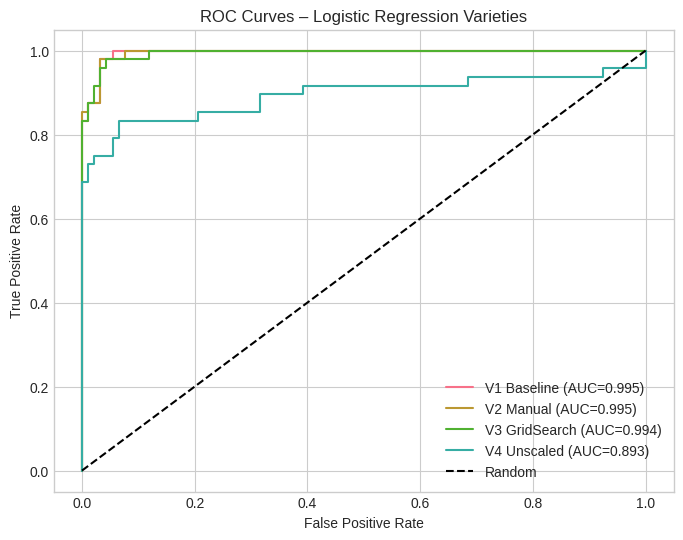

In [ ]:
# ROC Curves for all varieties
plt.figure(figsize=(8, 6))
for name, prob in [
    ("V1 Baseline", y_prob_v1),
    ("V2 Manual", y_prob_v2),
    ("V3 GridSearch", y_prob_v3),
    ("V4 Unscaled", y_prob_v4)
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves – Logistic Regression Varieties')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## 4. Validation Method

- **Train/Test split**: Stratified 80/20 (preserves class ratio).
- **Hyperparameter selection**: Stratified 5-Fold Cross-Validation inside `GridSearchCV`.
- **Primary scoring metric for tuning**: **F1-Score** (balances Precision & Recall – important because false negatives in cancer detection are costly).
- **Reported metrics**: Accuracy, Precision, Recall, F1, ROC-AUC on the held-out test set.

## 5. Conclusion

- Scaled features consistently outperform unscaled features for Logistic Regression.
- GridSearchCV finds a better regularisation strength than the default, improving F1 and Recall.
- Logistic Regression is highly suitable: high accuracy (>95 %), excellent ROC-AUC, and fully interpretable coefficients.
- **Recommended model for the group comparison**: Variety 3 (GridSearchCV best on scaled data).

## 6. Limitations & Possible Improvements

| Limitation | Improvement |
|------------|-------------|
| Assumes linear decision boundary | Could combine with polynomial features or switch to kernel methods |
| Sensitive to feature scaling | Always use scaled features (already done) |
| Class imbalance (≈2:1) | Could apply class_weight='balanced' or SMOTE |
| Small dataset | Nested CV or bootstrap for more stable estimates |
| No feature interaction terms | Explicit interaction features or tree-based models |


Feature importance (absolute coefficient magnitude):
                    Feature  Coefficient
                Bare_Nuclei     0.461892
   Uniformity_of_Cell_Shape     0.349320
            Clump_Thickness     0.347438
    Uniformity_of_Cell_Size     0.335994
            Bland_Chromatin     0.327644
            Normal_Nucleoli     0.293942
          Marginal_Adhesion     0.281852
Single_Epithelial_Cell_Size     0.248820
                    Mitoses     0.184485


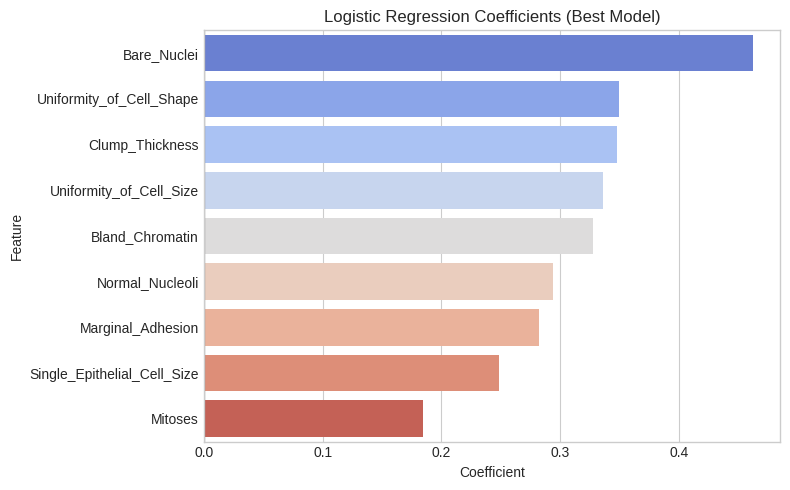

In [ ]:
# Optional: show coefficients of the best model (interpretability)
best_lr = lr_v3
coef_df = pd.DataFrame({
    'Feature': feature_cols_orig,
    'Coefficient': best_lr.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False)
print("Feature importance (absolute coefficient magnitude):")
print(coef_df.to_string(index=False))

plt.figure(figsize=(8, 5))
sns.barplot(data=coef_df, x='Coefficient', y='Feature', palette='coolwarm')
plt.title('Logistic Regression Coefficients (Best Model)')
plt.axvline(0, color='black', lw=0.8)
plt.tight_layout()
plt.show()